<a href="https://colab.research.google.com/github/jihyeon26/computational-language-technology-hs26/blob/main/stage2/work_packages/stage2_wp1_embeddings.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tracking Open Models in AI Media · Stage 2: Advanced Embedding Models Training and Analysis
The previous stage cleaned the AI Media Dataset, analysed it with counts, topics and entities, and built a knowledge graph of the open-models track. Stage 2 turns the language of the corpus into vector representations and compares two families of models :
- **Classical representations** : trained from scratch on the corpus: word embeddings (Word2Vec, FastText) and document embeddings (Doc2Vec);
- **Compact open models**, pre-trained language models adapted to the corpus with parameter-efficient fine-tuning.

The goal is to find out which representations best capture the AI media discourse, at what cost, and how well they handle the open-models track. Stage 2 uses the full corpus, but includes analyses focused on the track: model families, developers, openness concepts and related trends.

## Stage 2 requirements and where they are addressed
| Requirement (project brief) | Section |
|---|---|
| Preprocessing for embeddings, training/validation splits | 1.1|
| Training of embeddings with Word2Vec, FastText and Doc2Vec | 1.2 |
| Visualisation of semantic clusters and thematic overlaps| 1.3 |
| Selection of compact open model(s) and parameter-efficient fine-tuning (LoRA/QLoRA) | x |
| Intrinsic evaluation (semantic similarity, clustering quality, visualisation) | x |
| Extrinsic task relevant to the track | x |
| Comparison of trade-offs: model size, performance, training speed, GPU requirements | x |
| Insight extraction with the best models, focused analysis of the track | x |

## Expected outputs
- Notebook with the model training and fine-tuning steps, clearly annotated
- Visualisations comparing embeddings and model outputs
- A short summary of the model trade-offs and of the insights on the open-models track

## Link with the other stages
- **Input from Stage 1**: the cleaned corpus, the open-models relevance tiers, the WP1 lexicon (normalisation of model names and acronyms), the topics and the extracted entities.
- **Output for Stage 3**: the best-performing representations can be used to retrieve passages in the question-answering (RAG) system.

## Contributions
The work was split into three consecutive parts, each building on the previous one.
| Team member | Sections | Contribution |
|---|---|---|
| Jennifer Spieser | 1.1, 1.2, 1.3 | data preparation for embeddings; Word2Vec, FastText and Doc2Vec; visualisation of semantic clusters and thematic overlaps |
| Jihyeon Choung | x | selection of compact open model(s), LoRA/QLoRA fine-tuning, documentation of the training setup and resources |
| Daliasny Gonzalez Guzman | x | intrinsic evaluation, extrinsic task, comparison of trade-offs (size, performance, training speed, GPU), insight extraction on the track |

All work packages use the same training / validation split (`artifacts/stage2_wp1/splits.parquet`), so that every model is trained and evaluated on the same articles.

# 1. Classical Word and Sentence Embeddings
The objective of this first part is to build the classical representations :
1. **Data preparation for embeddings** : preprocess the corpus for training and prepare training/validation splits
2. **Classical word and sentence embeddings** : train Word2Vec, FastText and Doc2Vec, and visualise the semantic clusters and thematic overlaps of AI discourse, including the terms of the open-models track.

The data used is the full cleaned corpus as embeddings need a lot of text to be stable. Therefore, the full corpus is used for training and the analyses focus on the terms and articles of the open-model track.

**Cache**: every long step, such as training models, saves its result in `OUT_DIR`(Google Drive). When the notebook is run again, each step first checks whether its file already exists: if it does, the file is loaded; if not, it is created.



## 1.1 Data Preparation for Embeddings
### 1.1.1 Setup and configuration
We load:
- `corpus_clean.parquet`: the cleaned corpus of Stage 1, with the relevance tier of each article for the open-models track (`om_tier`: core, reference, mention, none). The API reference pages (`is_api_reference`) are left out, as in the Stage 1 topic models: they contain code signatures rather than media discourse.
- `open_models_core.parquet`: the 1,210 core articles of the track with their Stage 1 topic
- the WP1 lexicon (`open_models_lexicon.json`): model families, ecosystem tools, openness concepts and normalisation rules


In [1]:
from pathlib import Path
import os

# Clone the project repository
REPO = Path("/content/computational-language-technology-hs26")
if REPO.exists():
    !git -C {REPO} pull -q
else:
    !git clone -q https://github.com/jihyeon26/computational-language-technology-hs26.git {REPO}

# Mount Google Drive (input data and outputs)
from google.colab import drive
drive.mount("/content/drive")

# Inputs: Stage 1 outputs
DATA_DIR = Path("/content/drive/MyDrive/HSLU/CLT/data/processed")

# Outputs of this notebook (also used as cache), with a sub-folder for the figures
OUT_DIR = Path("/content/drive/MyDrive/HSLU/CLT/extraction_outputs/stage2/wp1")
FIG = OUT_DIR / "figures"
FIG.mkdir(parents=True, exist_ok=True)

Mounted at /content/drive


In [2]:
# Libraries
import json, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Fix the seed
SEED = 42

# Cosine
def unit(X):
    return X / np.maximum(np.linalg.norm(X, axis=1, keepdims=True), 1e-9)

# Save figure and show it
def save_fig(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

# Stage 1 outputs
corpus = pd.read_parquet(DATA_DIR / "corpus_clean.parquet",
                         columns=["doc_id", "quarter", "text", "om_tier", "is_api_reference"])

# Leave out the API reference pages (code signatures, not media discourse), as in the Stage 1 topic models
corpus = corpus[~corpus["is_api_reference"]].drop(columns="is_api_reference").reset_index(drop=True)
core = pd.read_parquet(DATA_DIR / "open_models_core.parquet", columns=["doc_id", "dominant_topic_label"])
lexicon = json.loads((REPO / "artifacts/stage1_wp1/lexicon/open_models_lexicon.json").read_text(encoding="utf-8"))

print(f"{len(corpus):,} articles | {corpus['text'].str.split().str.len().sum() / 1e6:.1f} M words")
print(corpus["om_tier"].value_counts().to_string())

45,462 articles | 68.3 M words
om_tier
none       41425
mention     2827
core        1210


### 1.1.2 Normalisation

The normalisation reduces the variations in word forms to a common form when the variations mean the same thing. It is important for embeddings, because a vector is learned from the contexts of one token. For instance, if *LLaMa* and *Llama* stay different tokens, their contexts are split over several vectors and none of them is well learned. We therefore reuse the WP1 lexicon of Stage 1, including its normalisation rules, so that both Stage 1 and 2 use the same entities.

In [3]:
# Matching view of WP1
MATCH_MAP = str.maketrans({"‐": "-", "‑": "-", "‒": "-", "–": "-", "−": "-",
                           "‘": "'", "’": "'", "“": '"', "”": '"', "…": "...",
                           " ": " ", "ﬁ": "fi", "ﬂ": "fl"})

# Normalisation rules of the WP1 lexicon, compiled once
CANON_RULES = []
for fid, f in lexicon["families"].items():            # model families: "LLaMA" -> "llama"
    CANON_RULES.append((re.compile(f["rx"]), fid, f.get("kw", []), False))
for tid, t in lexicon["ecosystem"].items():           # ecosystem tools: "Hugging Face" -> "hugging_face"
    CANON_RULES.append((re.compile(t["rx"]), tid, t.get("kw", []), False))
for cid, c in lexicon["concepts"].items():            # openness concepts: "open weights" -> "open_weight"
    CANON_RULES.append((re.compile(c["rx"]), cid, [k.lower() for k in c.get("kw", [])], True))
for rx, norm in lexicon["phrase_normalisation"]:      # acronyms and phrases: "U.S." -> "united_states"
    CANON_RULES.append((re.compile(rx), norm.strip().replace(" ", "_"), [], False))

def normalise(text):
    text = text.translate(MATCH_MAP)
    lower = text.lower()
    for rx, token, triggers, lower_triggers in CANON_RULES:
        # Speed-up (as in WP1): a pattern only runs if one of its trigger words is in the text
        if triggers and not any(k in (lower if lower_triggers else text) for k in triggers):
            continue
        text = rx.sub(f" {token} ", text)
    return text

### 1.1.3 Sentence and Word Tokenisation
After normalisation, each article is split into sentences, and each sentence into tokens:
- **Sentences**: Word2Vec and FastText learn a word from the words around it, within a sentence. The articles are therefore split into paragraphs, then into sentences (a sentence ends with `.`, `!` or `?`, followed by a capital letter or a digit). Abbreviations such as *U.S.*, which could be mistaken for the end of a sentence, are already replaced by `united_states` during normalisation. Sentences with fewer than 3 tokens (headings, captions, menu items) are dropped.
- **Words**: the text is lower-cased so that *Meta* and *meta* are the same token. A token is a sequence of letters and digits that can contain `_`, `-`, `.` or `'` inside (`gpt-4o`, `llama_cpp`, `don't`), so that model names and canonical tokens stay in one piece; punctuation is dropped. Pure numbers (`2025`, `70`) are dropped because they carry no meaning on their own. The possessive *'s* is removed so that an organisation and its possessive form share one vector.

In addition, stop words are kept, as an embedding learns a word from its context and removing them would change the neighbours of every word; very frequent words are down-sampled during training instead. Similarly, no lemmatisation is applied, so that the word forms keep their information.


In [4]:
# Sentence boundary
SENT_SPLIT = re.compile(r'(?<=[.!?])["\')\]]?\s+(?=["(\[]?[A-Z0-9])')

# Token - letters / digits
TOKEN_RX = re.compile(r"[a-z0-9]+(?:[_\-.'][a-z0-9]+)*")
MIN_SENT_TOKENS = 3

# Lower case, possessive and pure numbers
def tokenize(sentence):
    sentence = re.sub(r"'s\b", "", sentence.lower())
    return [t for t in TOKEN_RX.findall(sentence) if not t.replace(".", "").isdigit()]

# Split article into tokenised sentences
def doc_sentences(text):
    sentences = []
    for paragraph in text.split("\n"):
        for sentence in SENT_SPLIT.split(paragraph.strip()):
            tokens = tokenize(sentence)
            if len(tokens) >= MIN_SENT_TOKENS:
                sentences.append(tokens)
    return sentences

In [7]:
# Example of a core article
core_texts = corpus.loc[corpus["om_tier"] == "core", "text"]
example = next(t for t in core_texts if "open-weight" in t or "open weight" in t)
pos = min(i for i in (example.find("open-weight"), example.find("open weight")) if i >= 0)
cut = example.rfind(". ", 0, max(0, pos - 150))
start = cut + 2 if cut >= 0 else 0
passage = example[start:start + 350]


print("ORIGINAL TEXT:\n", passage, "\n")
print("NORMALISED TEXT:\n", normalise(passage), "\n")
print("TOKENISED SENTENCES:")
for s in doc_sentences(normalise(passage)):
    print("  ", s)

ORIGINAL TEXT:
 Fast inference allows for more frequent API calls without bogging down time to output, which is essential for agentic workflows and real-time decision making.

We’re thinking: Models with open weights are now served faster than proprietary models and are nearly as capable. This may spur further adoption of open models as well as prompting strategie 

NORMALISED TEXT:
 Fast inference allows for more frequent API calls without bogging down time to output, which is essential for agentic workflows and real-time decision making.

We're thinking: Models with  open_weight  are now served faster than proprietary models and are nearly as capable. This may spur further adoption of  open_model  as well as prompting strategie 

TOKENISED SENTENCES:
   ['fast', 'inference', 'allows', 'for', 'more', 'frequent', 'api', 'calls', 'without', 'bogging', 'down', 'time', 'to', 'output', 'which', 'is', 'essential', 'for', 'agentic', 'workflows', 'and', 'real-time', 'decision', 'making']
   [

### 1.1.4 Training and validation splits
The split is made by article (all sentences of an article are in the same split) and stratified by relevance tier (core, mention, none) so that both splits contain the same share of open-models articles: 80% of the articles for training and 20% for validation.

The embeddings are trained on the training split only. The split is fixed with a seed and saved (`splits.parquet`), so that all work packages of Stage 2 use the same articles.

The tokenised corpus is saved as text files:
- `sentences_train.txt`: one training sentence per line
- `docs_all.txt`: one article per line, all splits, with `docs_index.parquet` mapping each line to its article

In [8]:
from sklearn.model_selection import train_test_split

VALIDATION_SHARE = 0.2
SPLITS_PATH = OUT_DIR / "splits.parquet"

# Training/validation split
if SPLITS_PATH.exists():
    splits = pd.read_parquet(SPLITS_PATH)
    print("Split loaded from", SPLITS_PATH.name)
else:
    # stratify by relevance tier
    stratum = corpus["om_tier"].replace({"reference": "mention"}).to_numpy(dtype=object)
    train_ids, val_ids = train_test_split(corpus["doc_id"].to_numpy(dtype=object), test_size=VALIDATION_SHARE,
                                          random_state=SEED, stratify=stratum)
    splits = pd.DataFrame({"doc_id": corpus["doc_id"],
                           "split": np.where(corpus["doc_id"].isin(set(train_ids)), "train", "validation")})
    splits = splits.merge(corpus[["doc_id", "om_tier", "quarter"]], on="doc_id")
    splits.to_parquet(SPLITS_PATH, index=False)
    print("Split created and saved to", SPLITS_PATH.name)

corpus["split"] = corpus["doc_id"].map(dict(zip(splits["doc_id"], splits["split"])))
corpus["track"] = corpus["om_tier"].ne("none")
display(pd.crosstab(corpus["om_tier"], corpus["split"], margins=True))

# Apply normalisation and tokenize
SENT_PATH, DOCS_PATH, INDEX_PATH = OUT_DIR / "sentences_train.txt", OUT_DIR / "docs_all.txt", OUT_DIR / "docs_index.parquet"
docs_index = corpus[["doc_id", "split", "om_tier", "track"]].copy()     # line i of docs_all.txt = row i of corpus
is_train = docs_index["split"].eq("train").to_numpy()

if not (SENT_PATH.exists() and DOCS_PATH.exists() and INDEX_PATH.exists()):
    n_tokens = []
    with open(SENT_PATH, "w", encoding="utf-8") as fs, open(DOCS_PATH, "w", encoding="utf-8") as fd:
        for i, text in enumerate(corpus["text"]):
            sentences = doc_sentences(normalise(text))
            if is_train[i]:
                fs.writelines(" ".join(s) + "\n" for s in sentences)
            fd.write(" ".join(t for s in sentences for t in s) + "\n")
            n_tokens.append(sum(len(s) for s in sentences))
    docs_index["n_tokens"] = n_tokens
    docs_index.to_parquet(INDEX_PATH, index=False)
    print("Tokenised corpus created")
else:
    print("Tokenised corpus loaded")
docs_index = pd.read_parquet(INDEX_PATH)

Split loaded from splits.parquet


split,train,validation,All
om_tier,,,
core,968,242,1210
mention,2262,565,2827
none,33139,8286,41425
All,36369,9093,45462


Tokenised corpus loaded


In [9]:
# Summary of the tokenised corpus
n_sent = sum(1 for _ in open(SENT_PATH, encoding="utf-8"))
print(f"Articles: {len(docs_index):,} | training sentences: {n_sent:,} | "
      f"average tokens per article: {docs_index['n_tokens'].mean():.0f}")
print("Tokens per split (M):", (docs_index.groupby("split")["n_tokens"].sum() / 1e6).round(1).to_dict())

Articles: 45,462 | training sentences: 2,691,317 | average tokens per article: 1464
Tokens per split (M): {'train': 53.1, 'validation': 13.5}


## 1.2 Classical Word and Sentence Embeddings
### 1.2.1 Word Embeddings: Word2Vec
Word2Vec learns a vector for each word by trying to predict the words around it. Regarding the settings, most values are the default of `gensim` and are not tuned since this is done later in the notebook.


In [10]:
!pip install -q gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 49.0 MB/s eta 0:00:00


In [11]:
from gensim.models import Word2Vec, FastText

# Settings
EMB = dict(vector_size=100, window=5, min_count=10, sample=1e-4, negative=5, epochs=5, sg=1)

def train_or_load(cls, path, **params):
    if path.exists():
        print(f"{path.name}: loaded")
        return cls.load(str(path))

    model = cls(corpus_file=str(SENT_PATH), seed=SEED, **params)
    model.save(str(path))
    print(f"{path.name}: trained and saved")
    return model

w2v = train_or_load(Word2Vec, OUT_DIR / "word2vec.model", **EMB)
print(f"Vocabulary: {len(w2v.wv):,} words")

word2vec.model: loaded
Vocabulary: 63,043 words


Training a model does not guarantee that the vectors are meaningful. As a quick check, we look at the most similar words to a few known terms of the track, using cosine similarity: if the vectors are meaningful, a model family should be close to other model families. We also look up a few model names that do not exist and therefore never appeared in the training data.

In [13]:
TRACK_TERMS = ["llama", "deepseek", "qwen", "mistral"]
UNSEEN = ["qwen999-max", "llama-999", "deepseek-r999"]

def neighbours(model, term, k=8):
    if term not in model.wv.key_to_index and not isinstance(model, FastText):
        return "(not in vocabulary: no vector)"
    return ", ".join(f"{w} ({s:.2f})" for w, s in model.wv.most_similar(term, topn=k))

with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame({"term": TRACK_TERMS + UNSEEN,
                          "Word2Vec neighbours": [neighbours(w2v, t) for t in TRACK_TERMS + UNSEEN]}))

,term,Word2Vec neighbours
0,llama,"qwen (0.85), 8b (0.84), 70b (0.84), mistral (0.83), 7b (0.83), gemma (0.83), 405b (0.83), 3.1-8b (0.82)"
1,deepseek,"r1 (0.91), kimi (0.81), k3 (0.81), r1-0528 (0.80), r1-zero (0.80), o1 (0.79), o3-mini (0.79), v3.2-exp (0.79)"
2,qwen,"32b (0.85), llama (0.85), kimi (0.84), 7b (0.83), gpt_oss (0.82), gemma (0.82), 30b-a3b (0.81), 6-27b (0.80)"
3,mistral,"llama (0.83), sarvam (0.80), 8x7b (0.78), ai21 (0.78), 3.3-70b-instruct (0.77), 7b (0.76), llava (0.75), 32b (0.75)"
4,qwen999-max,(not in vocabulary: no vector)
5,llama-999,(not in vocabulary: no vector)
6,deepseek-r999,(not in vocabulary: no vector)


The nearest neighbours of the model families are mostly other open-model families and parameter sizes (e.g. *llama* → *qwen*, *mistral*, *70b*). The three invented names receive no vector at all: Word2Vec only knows words seen at least 10 times in the training split, so any new or rare model name is out of vocabulary. This limitation motivates the use of FastText.

### 1.2.2 Word Embeddings: FastText
FastText should answer the previous limitation; it is a skip-gram whose word vector is the sum of the vectors of its character n-grams. As a result, words that share pieces of spelling share part of their vector, and a vector can be built for any word, even one never seen in training, from the n-grams it contains.

It uses the same settings as Word2Vec, so that both models can be compared.


In [14]:
FT_NGRAMS = dict(min_n=3, max_n=5, bucket=500_000)

ft = train_or_load(FastText, OUT_DIR / "fasttext.model", **EMB, **FT_NGRAMS)

fasttext.model: loaded


In [15]:
# Comparison of Word2Vec and FastText
nn_table = pd.DataFrame({"term": TRACK_TERMS + UNSEEN,
                         "Word2Vec": [neighbours(w2v, t) for t in TRACK_TERMS + UNSEEN],
                         "FastText": [neighbours(ft, t) for t in TRACK_TERMS + UNSEEN]})
with pd.option_context("display.max_colwidth", None):
    display(nn_table)

,term,Word2Vec,FastText
0,llama,"qwen (0.85), 8b (0.84), 70b (0.84), mistral (0.83), 7b (0.83), gemma (0.83), 405b (0.83), 3.1-8b (0.82)","llama2 (0.90), llama3.2 (0.90), llama3 (0.89), qwen (0.86), llamav-o1 (0.85), 8b (0.85), 70b (0.84), gpt_oss (0.83)"
1,deepseek,"r1 (0.91), kimi (0.81), k3 (0.81), r1-0528 (0.80), r1-zero (0.80), o1 (0.79), o3-mini (0.79), v3.2-exp (0.79)","r1 (0.92), deepset (0.85), kimi (0.83), deepswe (0.81), qwen (0.80), open_source_model (0.79), open_weight (0.79), 32b (0.78)"
2,qwen,"32b (0.85), llama (0.85), kimi (0.84), 7b (0.83), gpt_oss (0.82), gemma (0.82), 30b-a3b (0.81), 6-27b (0.80)","gemma (0.88), 32b (0.87), llama (0.86), llama3.2 (0.85), kimi (0.85), k2.5 (0.84), gemma2 (0.84), 7b (0.84)"
3,mistral,"llama (0.83), sarvam (0.80), 8x7b (0.78), ai21 (0.78), 3.3-70b-instruct (0.77), 7b (0.76), llava (0.75), 32b (0.75)","llama (0.80), qwen (0.78), sarvam (0.78), 32b (0.76), open_weight (0.76), open_source_model (0.76), gpt_oss (0.76), 7b (0.75)"
4,qwen999-max,(not in vocabulary: no vector),"7-max (0.93), qwen (0.86), 6-27b-fable-fusion-711-uncensored-heretic-nm-dau-neo-max-mtp (0.84), k2.5 (0.84), bc-max (0.83), kimi (0.83), gpt-5.1-codex-max (0.82), 235b-a22b (0.82)"
5,llama-999,(not in vocabulary: no vector),"llama2 (0.96), llama3 (0.95), llama3.2 (0.95), meta-llama (0.89), llamav-o1 (0.88), llamaparse (0.87), llama (0.87), 3.1-8b (0.86)"
6,deepseek-r999,(not in vocabulary: no vector),"deepseek (0.96), r1 (0.89), deepset (0.88), deepswe (0.83), qwen (0.83), kimi (0.83), k2.5 (0.82), deepsearch (0.82)"


FastText gives a vector to the three invented names, and their neighbours are meaningful: *llama-999* is close to *llama2*, *llama3* and *meta-llama*, and *deepseek-r999* to *deepseek* and *r1*. For known words, FastText also groups the versions of a family (*llama* → *llama2*, *llama3.2*; *gemma* → *gemma2*, *gemma3*), because these tokens share character n-grams.

The drawback is that similar spelling also creates false neighbours: *deepseek* is close to *deepset* and *deepsearch*, *llama-999* to the tool *llamaparse*, and *qwen999-max* to other "-max" models such as *gpt-5.1-codex-max*.

Word2Vec neighbours therefore reflect context only, while FastText neighbours reflect both context and spelling.

### 1.2.3 Sentence embeddings
We use Doc2Vec, which extends Word2Vec from words to text: each text gets its own vector, trained together with the word vectors. It uses the same settings as the word embeddings, except 10 epochs : a text vector is only updated when its text is read, once per pass, so it needs more passes than a frequent word.

The unit is the article. The model is trained on the training articles, and the vectors of the validation articles are inferred with the trained model, since articles not seen during training have no vector in the model. Word2Vec and FastText, in contrast, produce one vector per word, so a new text only requires looking up its words in the trained vocabulary.

In [16]:
from gensim.models.doc2vec import Doc2Vec

# Settings of Doc2Vec
D2V = dict(vector_size=100, min_count=10, sample=1e-4, negative=5, epochs=10, dm=0)
DOCS_TRAIN_PATH, D2V_PATH, DOCVEC_PATH = OUT_DIR / "docs_train.txt", OUT_DIR / "doc2vec.model", OUT_DIR / "doc_vectors.parquet"
train_lines = np.flatnonzero(is_train)

# Training articles
if not DOCS_TRAIN_PATH.exists():
    with open(DOCS_PATH, encoding="utf-8") as fin, open(DOCS_TRAIN_PATH, "w", encoding="utf-8") as fout:
        fout.writelines(line for i, line in enumerate(fin) if is_train[i])

# Doc2Vec model
if D2V_PATH.exists():
    d2v = Doc2Vec.load(str(D2V_PATH))
    print("doc2vec.model: loaded")
else:
    d2v = Doc2Vec(corpus_file=str(DOCS_TRAIN_PATH), seed=SEED, **D2V)
    d2v.save(str(D2V_PATH))
    print("doc2vec.model: trained and saved")

# One vector per article
if DOCVEC_PATH.exists():
    doc_vectors = pd.read_parquet(DOCVEC_PATH)
    print("doc_vectors.parquet: loaded")
else:
    tag_of = {line: tag for tag, line in enumerate(train_lines)}
    with open(DOCS_PATH, encoding="utf-8") as f:
        vectors = [d2v.dv[tag_of[i]] if is_train[i] else d2v.infer_vector(line.split(), epochs=D2V["epochs"])
                   for i, line in enumerate(f)]
    doc_vectors = docs_index[["doc_id", "split", "om_tier", "track"]].assign(vector=vectors)
    doc_vectors.to_parquet(DOCVEC_PATH, index=False)
    print("doc_vectors.parquet: created and saved")
DOC = np.vstack(doc_vectors["vector"].to_numpy())

doc2vec.model: loaded
doc_vectors.parquet: loaded


In [17]:
# Example
for sentence in ["Meta released the weights of its new model under a permissive licence.",
                 "The Chinese startup trained its model at a fraction of the cost of American rivals."]:
    tokens = [t for s in doc_sentences(normalise(sentence)) for t in s]
    v = d2v.infer_vector(tokens, epochs=D2V["epochs"])
    best = [train_lines[tag] for tag, _ in d2v.dv.most_similar([v], topn=3)]
    print(f"\n{sentence}")
    for i in best:
        print("   -", corpus.loc[i, "text"][:140].replace("\n", " "))


Meta released the weights of its new model under a permissive licence.
   - OpenAI has finally done it: after months of promises, the ChatGPT hitmaker has released its first open-weight large language models (LLMs) s
   - DeepSeek took the AI monopoly by storm last month, and the industry is still grappling to find an appropriate response to the underdog’s sen
   - Meta will release a selection of its AI models under an open-source license. The models in question come under the purview of Meta’s chief A

The Chinese startup trained its model at a fraction of the cost of American rivals.
   - Chinese artificial intelligence firm DeepSeek rocked markets this week with claims its new AI model outperforms OpenAI's and cost a fraction
   - Chinese President Xi Jinping called for global cooperation on artificial intelligence, warning against countries placing their own national 
   - A bipartisan House committee on Wednesday recommended placing restrictions on the export of AI models to Chi

Both queries retrieve articles on the same subject. The Meta query returns three open-model releases, with the Meta article only third, so the subject weighs more than the company name. The second query does not name Deepseek but retrieves two DeepSeek articles; the second result only shares the broader theme of China and AI, showing that Doc2Vec captures the general topical rather than a specified claim.

## 1.3 Visualisation
### 1.3.1 Semantic Clusters
Terms of AI discourse, grouped into categories, are projected from 100 dimensions to 2 with t-SNE (cosine distance), which keeps close words close. Words of the same category forming a group show a semantic cluster. As t-SNE keeps local neighbourhoods but not global distance, the distance between the groups on the map is not meaningful.

The terms and their categories come from Stage 1: the open-model families, openness concepts and ecosystem tools of the WP1 lexicon, and the most mentioned entities of each type extracted in WP2 (companies, other AI models, hardware, platforms, architectures, countries). The WP2 entities are used with the node corrections made during the Stage 1 knowledge-graph construction (name variants merged, aliases and type errors corrected, generic entities removed), since the category of a term is its colour on the map. Only names of entities are kept (a name contains a capital letter, a digit or `_`), and only terms that are single tokens of the vocabulary are shown.

### 1.3.1 Semantic Clusters



In [18]:
import json, re, unicodedata
from IPython.utils.capture import capture_output

# Categories of terms from Stage 1 - WP1 lexicon and WP2 entity
TOP_PER_TYPE = 12
WP2_TYPES = {"AI_MODEL": "other AI model", "COMPANY": "company", "HARDWARE": "hardware", "PLATFORM": "platform",
             "ARCHITECTURE": "architecture", "GPE": "country / region"}

def to_token(name):
    tokens = tokenize(normalise(str(name)))
    return tokens[0] if len(tokens) == 1 and tokens[0] in w2v.wv.key_to_index else None

CATEGORIES = {"open-model family (WP1)": list(lexicon["families"]),
              "openness concept (WP1)": list(lexicon["concepts"]),
              "ecosystem tool (WP1)": list(lexicon["ecosystem"])}

# WP2 entities with the node corrections - (stage1_final.ipynb, Section 5.9.3)
nodes = pd.read_csv(REPO / "artifacts/stage1_wp2/nodes.csv", keep_default_na=False, na_values=[""])
nodes[["first_seen", "last_seen"]] = nodes[["first_seen", "last_seen"]].apply(pd.to_datetime, errors="coerce")
stage1_nb = json.loads((REPO / "stage1/stage1_final.ipynb").read_text(encoding="utf-8"))
with capture_output():                                                      # hide the outputs of the Stage 1 cells
    for marker in ("def name_key(", "ALIAS_MAP = [", "def is_generic("):   # name variants, aliases/types, generic nodes
        code = next("".join(c["source"]) for c in stage1_nb["cells"]
                    if c["cell_type"] == "code" and marker in "".join(c["source"]))
        exec(code)                                                          # creates nodes_corrected
nodes = nodes_corrected[~nodes_corrected["is_generic"]]
# Only names of entities are kept: a name contains a capital letter, a digit or "_" (a WP1 canonical token)
nodes = nodes[nodes["entity"].astype(str).str.contains(r"[A-Z0-9_]")]

# WP2 categories
for entity_type, label in WP2_TYPES.items():
    top = nodes[nodes["entity_type"] == entity_type].sort_values("mentions", ascending=False)
    tokens = [to_token(e) for e in top["entity"]]
    tokens = [t for t in dict.fromkeys(tokens) if t]
    CATEGORIES[f"{label} (WP2)"] = tokens[:TOP_PER_TYPE]

# Terms of each category that have a vector
for cat, words in CATEGORIES.items():
    print(f"{cat:28}", ", ".join(w for w in words if w in w2v.wv.key_to_index)[:120])

open-model family (WP1)      llama, gemma, phi, nemotron, gpt_oss, granite, olmo, dbrx, arctic, smollm, eleuther, hermes, grok_open, mistral, eurollm
openness concept (WP1)       open_weight, open_source_model, open_model, osaid, weights_release, open_source_ai
ecosystem tool (WP1)         hugging_face, ollama, llama_cpp, vllm, gguf, lm_studio, lora
other AI model (WP2)         claude, r1, gpt-4, gpt-4o, gpt, agi, o1, gpt-5, manus, v3, gpt-3, o3
company (WP2)                deepseek, nvidia, openai, google, meta, anthropic, microsoft, alibaba, amazon, apple, ibm, cursor
hardware (WP2)               data_center, vram, tpus, h100, tpu, ram, a100, b200, h200, pcs, h100s, nvl72
platform (WP2)               gemini, github, chatgpt, azure, python, aws, android, bigquery, openclaw, openrouter, langchain, kubernetes
architecture (WP2)           mixture_of_experts, sft, chain_of_thought, ppo, rope, e2b, mamba, e4b, deltanet, a2a, mamba-2, swiglu
country / region (WP2)       united_states, china

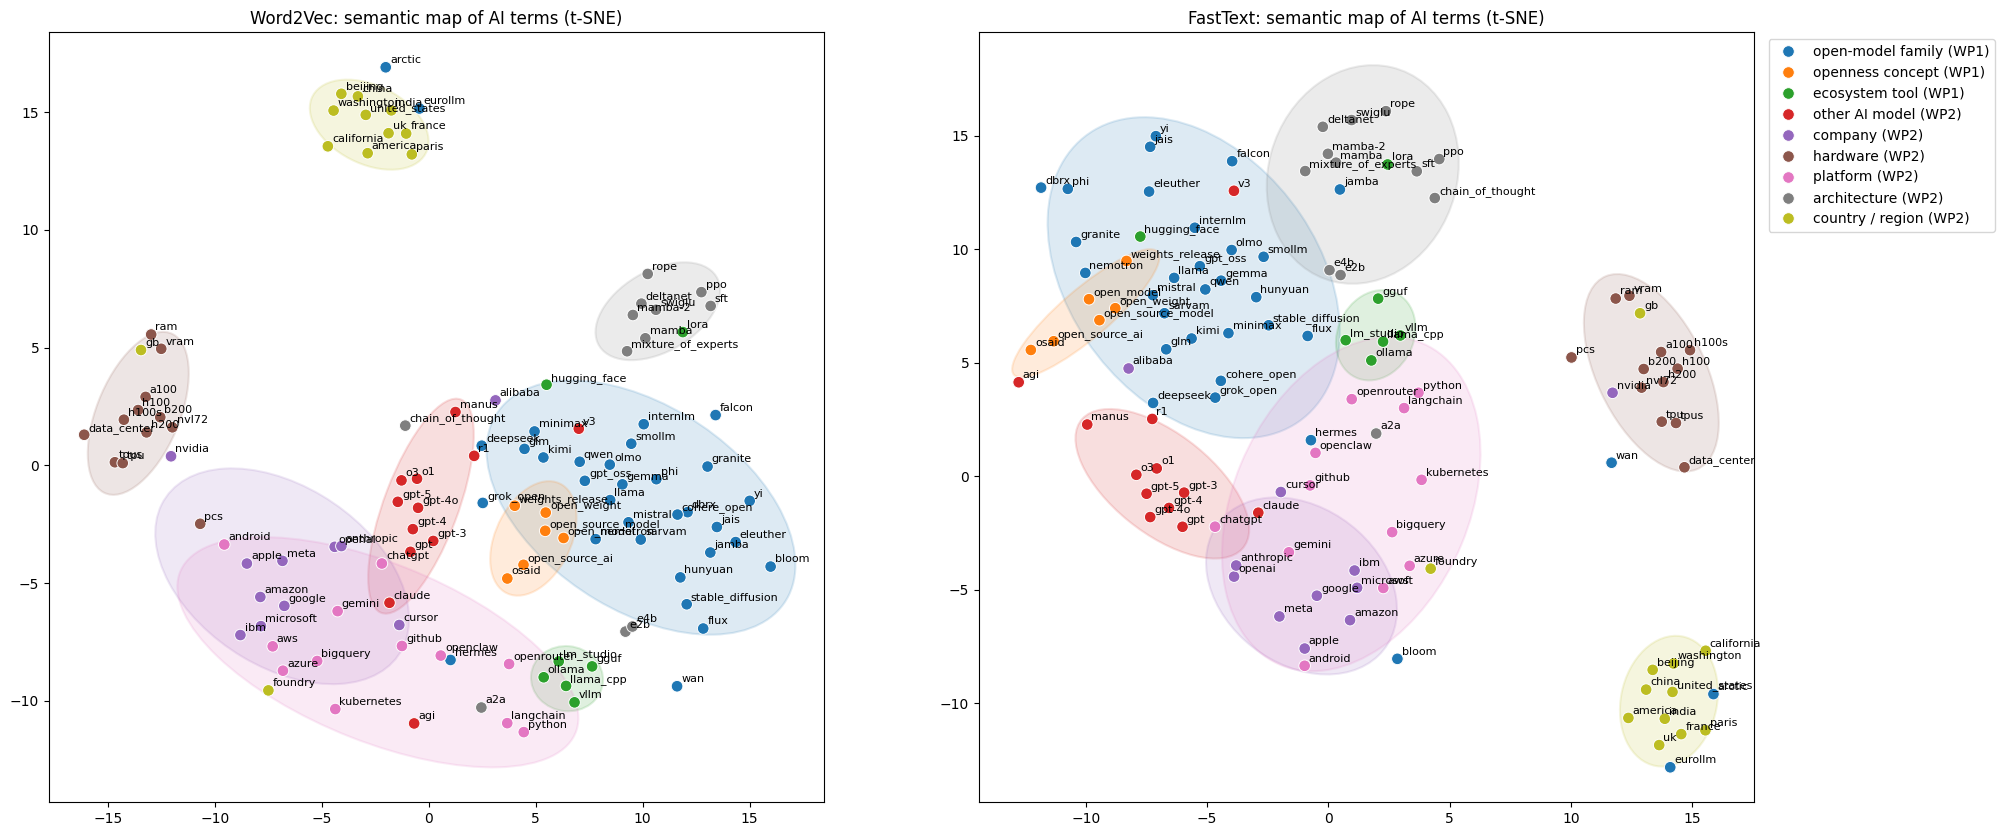

In [19]:
from sklearn.manifold import TSNE
from matplotlib.patches import Ellipse

# One row per term
rows, seen = [], set()
for cat, words in CATEGORIES.items():
    for w in words:
        if w in w2v.wv.key_to_index and w not in seen:
            rows.append((w, cat))
            seen.add(w)
terms = pd.DataFrame(rows, columns=["term", "category"])
palette = dict(zip(CATEGORIES, sns.color_palette("tab10", len(CATEGORIES))))

def draw_ellipse(ax, pts, color, n_std=2.0):
    dist = np.linalg.norm(pts - np.median(pts, axis=0), axis=1)
    pts = pts[dist <= 2.5 * np.median(dist)]
    if len(pts) < 3:
        return
    vals, vecs = np.linalg.eigh(np.cov(pts.T))
    angle = np.degrees(np.arctan2(vecs[1, 1], vecs[0, 1]))
    ax.add_patch(Ellipse(pts.mean(axis=0), 2 * n_std * np.sqrt(vals[1]), 2 * n_std * np.sqrt(vals[0]), angle=angle,
                         facecolor=color, edgecolor=color, alpha=0.15, lw=1.5))

# Same terms, two models: Word2Vec and FastText
fig, axes = plt.subplots(1, 2, figsize=(22, 10))
for ax, (name, model) in zip(axes, [("Word2Vec", w2v), ("FastText", ft)]):
    # t-SNE
    xy = TSNE(n_components=2, perplexity=min(15, len(terms) - 1), metric="cosine", init="pca",
              random_state=SEED).fit_transform(unit(model.wv[terms["term"].tolist()]))
    terms[f"x_{name.lower()}"], terms[f"y_{name.lower()}"] = xy[:, 0], xy[:, 1]

    # Zone of each category, then one point per term with its label
    for cat in CATEGORIES:
        mask = (terms["category"] == cat).to_numpy()
        if mask.any():
            draw_ellipse(ax, xy[mask], palette[cat])
    sns.scatterplot(x=xy[:, 0], y=xy[:, 1], hue=terms["category"], palette=palette, s=70, ax=ax,
                    legend=(name == "FastText"))
    for term, x, y in zip(terms["term"], xy[:, 0], xy[:, 1]):
        ax.annotate(term, (x, y), fontsize=8, xytext=(3, 3), textcoords="offset points")
    ax.set(title=f"{name}: semantic map of AI terms (t-SNE)", xlabel="", ylabel="")
axes[1].legend(bbox_to_anchor=(1.01, 1), loc="upper left")
terms.to_csv(OUT_DIR / "terms_tsne.csv", index=False)
save_fig(fig, "terms_tsne")

Both models give similar maps:
- **country / region** and **hardware** form separate zones;
- **company** and **platform** overlap strongly, while **other AI model** overlaps them less strongly, indicating that companies appear with their platforms;
- **ecosystem tool** overlaps **platform**;
- **openness concept** overlaps **open-model family**.

However, the models differ for **architecture** and **ecosystem tool**. In Word2Vec, **architecture** forms a separate zone, while in FastText it overlaps **open-model family**; **ecosystem tool** also overlaps slightly **open-model family** in FastText only.

In addition, in both models, terms of **open-model family** that are also common words are pulled towards their other meaning (*arctic* near **country / region** in Word2Vec), since classical embeddings give one vector per word, which mixes all its senses.

### 1.3.2 Thematic overlaps
Each article is a point, projected with t-SNE:
1. **Open-models discourse within AI discourse**: all track articles and a random sample of the other articles, coloured by relevance tier
2. **Themes of the track**: the 1,210 core articles coloured by their Stage 1 topic

All open-models articles (core, reference, mention) are shown, together with a random sample of 4,000 articles without open-model terms (fixed seed). The sample keeps the map readable, since these articles are the large majority of the corpus and would hide the track articles, and it keeps the t-SNE computation short. As a consequence, the map does not show the real proportions of the corpus.

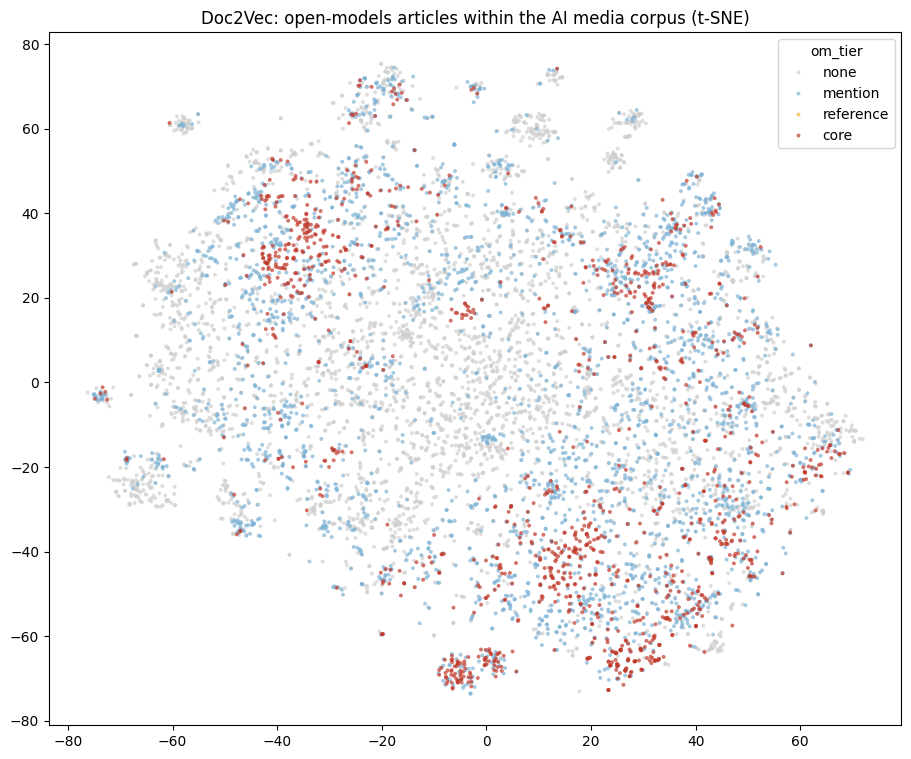

In [20]:
rng = np.random.default_rng(SEED)
track_idx = np.flatnonzero(doc_vectors["track"].to_numpy())
none_idx = np.flatnonzero(~doc_vectors["track"].to_numpy())
sample_idx = np.concatenate([track_idx, rng.choice(none_idx, size=min(len(none_idx), 4000), replace=False)])

# t-SNE
xy = TSNE(n_components=2, perplexity=30, metric="cosine", init="pca", random_state=SEED).fit_transform(unit(DOC[sample_idx]))
plot_df = doc_vectors.iloc[sample_idx][["om_tier"]].assign(x=xy[:, 0], y=xy[:, 1])
plot_df["om_tier"] = pd.Categorical(plot_df["om_tier"], ["none", "mention", "reference", "core"])
plot_df = plot_df.sort_values("om_tier")   # core articles drawn last (on top)

fig, ax = plt.subplots(figsize=(11, 9))
sns.scatterplot(data=plot_df, x="x", y="y", hue="om_tier", s=8, linewidth=0, alpha=0.7, ax=ax,
                palette={"none": "#cfcfcf", "mention": "#7fb3d5", "reference": "#f5b041", "core": "#c0392b"})
ax.set(title="Doc2Vec: open-models articles within the AI media corpus (t-SNE)", xlabel="", ylabel="")
save_fig(fig, "docs_tsne_tiers")

The tiers are largely mixed: *none*, *mention* and *core* articles appear over most of the map, so Doc2Vec does not separate well the open-models articles from the rest of the corpus.

- **core articles** are spread mainly over the right half, with a few denser concentrations (top left, bottom centre-right and one small tight group at the bottom)
- **mention articles** lie mostly in the outer part of the map, around the centre
- **none articles** appear everywhere and dominate the centre of the map
- **reference tier** contains very few articles and is hardly visible

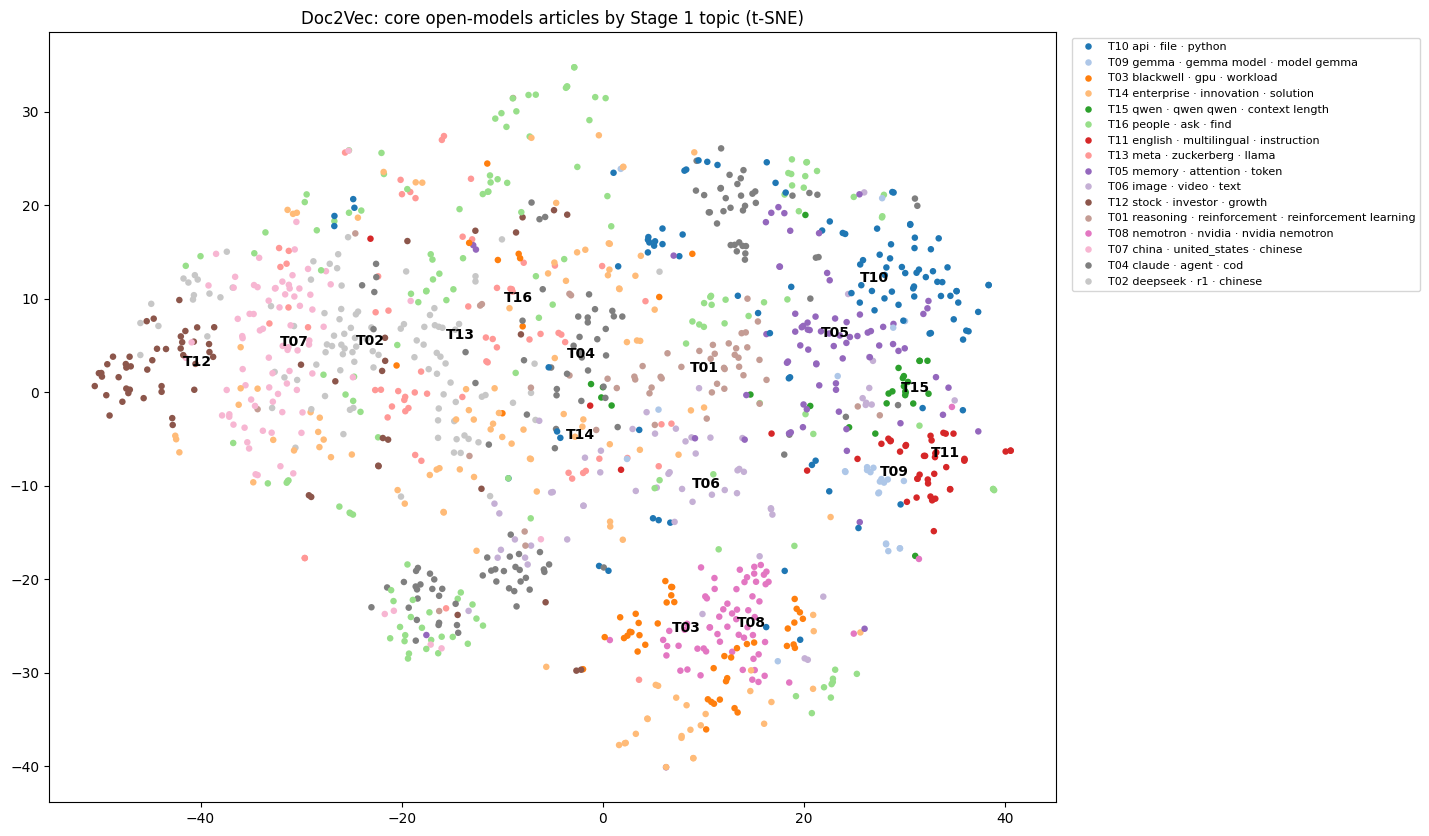

In [24]:
# Core articles of the track, coloured by their Stage 1 topic
core_vec = doc_vectors.merge(core, on="doc_id")
xy = TSNE(n_components=2, perplexity=30, metric="cosine", init="pca",
          random_state=SEED).fit_transform(unit(np.vstack(core_vec["vector"].to_numpy())))
core_vec["x"], core_vec["y"] = xy[:, 0], xy[:, 1]

fig, ax = plt.subplots(figsize=(13, 10))
sns.scatterplot(data=core_vec, x="x", y="y", hue="dominant_topic_label", s=22, linewidth=0, ax=ax, palette="tab20")
for topic, g in core_vec.groupby("dominant_topic_label"):          # topic number at the centre of its points
    ax.annotate(topic.split(" ")[0], (g["x"].median(), g["y"].median()), fontsize=10, weight="bold")
ax.set(title="Doc2Vec: core open-models articles by Stage 1 topic (t-SNE)", xlabel="", ylabel="")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
save_fig(fig, "core_docs_tsne_topics")



Doc2Vec was trained without the Stage 1 topics, yet several topics form their own zones, while the others are spread over the map:
- **T12** (*stock · investor · growth*) is isolated on the left edge of the map;
- **T03** (*blackwell · gpu · workload*) and **T08** (*nemotron · nvidia · nvidia nemotron*) lie close to each other at the bottom right, distinct from the other topics
- **T09** (*gemma · gemma model · model gemma*), **T11** (*english · multilingual · instruction*) and **T15** (*qwen · qwen qwen · context length*) also lie close to each other
- **T05** (*memory · attention · token*) and **T10** (*api · file · python*) lie close to each other

The other topics are spread over the map; for example, **T14** (*enterprise · innovation · solution*) and **T16** (*people · ask · find*) appear almost everywhere. For these topics, the label placed at the centre of their points does not mark a dense zone.

### 1.4 Outputs and handover
All outputs are saved in `OUT_DIR` on Google Drive (models and tokenised text are too large for GitHub); they also serve as a cache when the notebook is run again:

| file | content |
|---|---|
| `splits.parquet` | training / validation split of every article (seed 42), shared with the other Stage 2 work packages |
| `sentences_train.txt`, `docs_all.txt`, `docs_train.txt`, `docs_index.parquet` | tokenised corpus |
| `word2vec.model`, `fasttext.model` | word embeddings (`gensim`) |
| `doc2vec.model`, `doc_vectors.parquet` | sentence / document embeddings and the vector of every article |
| `terms_tsne.csv`, `figures/` | tables and visualisations |

### AI Disclosure
Claude Code was used as a coding assistant during the development of this work package. It supported:
- code improvement and optimisation;
- review pipeline design choices;
- reduction of processing time through code optimisation;
- preparation of the saved outputs.

All methodological choices, pipeline design, analysis, evaluation and interpretation of the results were conducted by the author of this work package. Claude Code was used solely as a coding and technical support tool.